# Global Codex Check

Compare the NATRE subset of the actual global output against the exact file loaded by Espe's notebook.

**Executed result: BITWISE PASS — 6,261 profiles, no missing or extra records; all 34 reference data variables and all three coordinates have identical dtypes and array bytes after independent profile ordering.**

The saved comparison section below includes:

- [Explanations and bitwise checks](#Bitwise-proof-against-the-file-Espe-actually-loaded): full global-inventory selection, annual counts, duplicate accounting, per-array byte checks and SHA-256 fingerprints, plus negative controls for signed zeros, NaN payloads and changed coverage.
- [Average profiles and plots](#Average-profiles-(no-bootstrap-uncertainty)): independently computed mean K_rho, Pdia and Piso = chi − Pdia, without bootstrap uncertainty; also six individual CT/SA profile overlays.

**The results and both figures are already saved in this notebook; no rerun is needed to view them.** The comparison section starts immediately after the `ds_NATRE` display cell. It can also be run independently without opening the complete global xarray dataset.

This proves agreement with Espe's saved profile arrays in NATRE. It does not independently validate the other global regions or the original scientific assumptions.


In [2]:
import matplotlib.pyplot as plt
import cmocean as cmo
import numpy as np
import pandas as pd
import xarray as xr

## Open the complete global profile dataset

The recovered manifest lists every main-run partition plus the repaired batch. 
The cell below creates one lazy xarray Dataset named `ds`; it reads file metadata first and loads numerical arrays only when requested. 
Profiles remain in partition order, and different floats can share a timestamp.

Use `.isel(...)` or a regional selection before `.compute()` to read a subset. 
Call `ds.close()` when finished to release open file handles.

The full open was verified with **1,117,885 profiles** across **25,686 files**, including the repaired batch. Opening the complete dataset took about **25 minutes** on this server; the numerical arrays remain lazy.


In [3]:
from pathlib import Path
import json

# This manifest includes both the main run and the recovered batch.
manifest_path = Path(
    "/swot/SUM05/amf2288/argo_mixing/global_repair_20261113/manifest.json"
)
manifest = json.loads(manifest_path.read_text())
if manifest["status"] != "complete" or manifest["failed_batches"]:
    raise ValueError("The global profile inventory is not complete.")

paths = [
    path
    for region in sorted(manifest["regions"])
    for path in sorted(manifest["regions"][region])
]
if not paths or len(paths) != len(set(paths)):
    raise ValueError("The manifest contains no files or duplicate file paths.")
print(f"Opening {len(paths):,} NetCDF partitions; opening all metadata can take about 25 minutes.", flush=True)

# Concatenate profile records explicitly: times overlap between files/floats.
# Arrays stay lazy; chunks follow the existing per-file profile batches.
ds = xr.open_mfdataset(
    paths,
    engine="netcdf4",
    combine="nested",
    concat_dim="time",
    data_vars="minimal",
    coords="minimal",
    compat="override",
    join="exact",
    combine_attrs="drop_conflicts",
    chunks={"time": -1},
)
if ds.sizes["time"] != manifest["accepted_profiles"]:
    ds.close()
    raise ValueError("Loaded profile count does not match the recovered manifest.")

# The repaired partition adds status 5 to the original flag definitions.
ds["gamma_n_status"].attrs.update(
    flag_values=np.arange(6, dtype=np.int16),
    flag_meanings="computed unsupported_latitude invalid_position no_samples failed_samples arithmetic_failure",
)
ds.attrs.update(
    source_manifest=str(manifest_path),
    accepted_profiles=manifest["accepted_profiles"],
    processing_stage=manifest["processing_stage"],
    summaries_status=manifest["summaries_status"],
)
print(f"ds contains {ds.sizes['time']:,} profiles, including the repaired batch.")
ds


Opening 25,686 NetCDF partitions; opening all metadata can take about 25 minutes.


/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'erddapy' loading failed:
cannot import name 'T_PathFileOrDataStore' from 'xarray.backends.common' (/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/common.py)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


ds contains 1,117,885 profiles, including the repaired batch.


<xarray.Dataset>
Dimensions:                           (time: 1117885, Z: 1000, Zfs: 39)
Coordinates:
  * time                              (time) datetime64[ns] 2012-12-31T13:03:...
  * Z                                 (Z) float64 2.0 4.0 ... 1.998e+03 2e+03
  * Zfs                               (Zfs) int64 50 100 150 ... 1850 1900 1950
Data variables: (12/48)
    longitude                         (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    latitude                          (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    MLD                               (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    pressure                          (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    Zmeas                             (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    CT                                (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    ...                                ...
    gamma_n_status                    (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    mixsea_status                     (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    polynomial_status                 (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    n2_status                         (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    gamma_n_failed_sample_count       (time) int32 dask.array<chunksize=(4,), meta=np.ndarray>
    stage_message                     (time) <U87 dask.array<chunksize=(4,), meta=np.ndarray>
Attributes:
    Description:                Fine-scale mixing estimates from Argo floats;...
    invalid_position_profiles:  0
    scientific_mode:            legacy_compatibility
    scientific_parameters:      {"dz": 2.0, "finescale_spacing": 50, "max_dep...
    legacy_conventions:         CT_from_t receives practical salinity; SA_fs ...
    source_mode:                local
    source_manifest:            /swot/SUM05/amf2288/argo_mixing/global_repair...
    accepted_profiles:          1117885
    processing_stage:           profiles
    summaries_status:           deferred

In [4]:
ds

<xarray.Dataset>
Dimensions:                           (time: 1117885, Z: 1000, Zfs: 39)
Coordinates:
  * time                              (time) datetime64[ns] 2012-12-31T13:03:...
  * Z                                 (Z) float64 2.0 4.0 ... 1.998e+03 2e+03
  * Zfs                               (Zfs) int64 50 100 150 ... 1850 1900 1950
Data variables: (12/48)
    longitude                         (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    latitude                          (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    MLD                               (time) float64 dask.array<chunksize=(4,), meta=np.ndarray>
    pressure                          (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    Zmeas                             (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    CT                                (Z, time) float64 dask.array<chunksize=(1000, 4), meta=np.ndarray>
    ...                                ...
    gamma_n_status                    (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    mixsea_status                     (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    polynomial_status                 (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    n2_status                         (time) int16 dask.array<chunksize=(4,), meta=np.ndarray>
    gamma_n_failed_sample_count       (time) int32 dask.array<chunksize=(4,), meta=np.ndarray>
    stage_message                     (time) <U87 dask.array<chunksize=(4,), meta=np.ndarray>
Attributes:
    Description:                Fine-scale mixing estimates from Argo floats;...
    invalid_position_profiles:  0
    scientific_mode:            legacy_compatibility
    scientific_parameters:      {"dz": 2.0, "finescale_spacing": 50, "max_dep...
    legacy_conventions:         CT_from_t receives practical salinity; SA_fs ...
    source_mode:                local
    source_manifest:            /swot/SUM05/amf2288/argo_mixing/global_repair...
    accepted_profiles:          1117885
    processing_stage:           profiles
    summaries_status:           deferred

## Subselect NATRE and compare

In [ ]:
# Match the Espe replication selection (2014–2023; upper bounds exclusive).
mask = (
    (ds.time >= np.datetime64("2014-01-01"))
    & (ds.time < np.datetime64("2024-01-01"))
    & (ds.latitude >= 19)
    & (ds.latitude < 32)
    & (ds.longitude >= -38)
    & (ds.longitude < -20)
).compute()

ds_NATRE = ds.isel(time=mask)


In [ ]:
ds_NATRE

## Bitwise proof against the file Espe actually loaded

Reference: cell 5 (zero based) of `plots_mixing_NATRE_gamman_analysis.ipynb`
loads `/swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc`.
The candidate below comes from the **actual recovered global manifest**, never
from an earlier NATRE replication run.

**Run from this section to skip the 25-minute full-global xarray open.** If `ds`
is already open, use its NATRE selection. Otherwise, scan positions in **every**
global file, apply exactly the same dates/bounds, and load only matching columns.
This avoids assuming the geographic folder names are correct. It performs no
profile reprocessing or bootstrap calculations.

Global partitions have a different storage order. Sort the candidate by time
and signed WMO/cycle UID (Argopy order), independently of the reference. Keep
Espe's original order. Check the complete population, retaining duplicate
time/longitude/latitude occurrences; never compare just an intersection.

**Bitwise** here means identical named dimensions, shapes, dtypes and decoded
NumPy array bytes in logical C order, including signed zeros and NaN payloads.
All 34 reference data variables and all three coordinates must pass. The global
files additionally contain 14 identity/diagnostic variables absent from Espe's
file; NetCDF compression, file bytes and attributes are outside this comparison.
No rounding, tolerances, interpolation or reference-based alignment is used.
This establishes NATRE equivalence; it does not independently validate other
global regions or the scientific assumptions of the original code.


In [1]:
from pathlib import Path
import hashlib
import json
import sys
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
from IPython.display import display, Markdown

code_dir = next(p for p in (Path.cwd(), Path.cwd() / "notebooks/espe_code")
                if (p / "natre_global_check.py").is_file())
if str(code_dir) not in sys.path:
    sys.path.insert(0, str(code_dir))
from natre_global_check import (
    natre_mask, canonical_order, load_global_natre,
    coverage_proof, array_proof, mean_profiles,
)

comparison_manifest = Path("/swot/SUM05/amf2288/argo_mixing/global_repair_20261113/manifest.json")
espe_path = Path("/swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc")
espe_notebook = json.loads((code_dir / "plots_mixing_NATRE_gamman_analysis.ipynb").read_text())
assert f'xr.open_dataset("{espe_path}")' in "".join(espe_notebook["cells"][5]["source"])

if "ds" in globals():
    inventory = json.loads(comparison_manifest.read_text())
    assert inventory["status"] == "complete" and not inventory["failed_batches"]
    assert ds.attrs.get("source_manifest") == str(comparison_manifest)
    assert ds.sizes["time"] == inventory["accepted_profiles"]
    # Identical mask to the selection cell above; compute only NATRE's arrays.
    mask = natre_mask(ds).compute()
    ds_NATRE = ds.isel(time=mask).compute()
    selection_audit = {
        "mode": "exact_mask_of_existing_complete_global_ds",
        "manifest": str(comparison_manifest),
        "manifest_sha256": hashlib.sha256(comparison_manifest.read_bytes()).hexdigest(),
        "global_profiles": ds.sizes["time"],
        "selected_profiles": ds_NATRE.sizes["time"],
    }
else:
    ds_NATRE, selection_audit = load_global_natre(comparison_manifest, workers=4)

natre_global = canonical_order(ds_NATRE)
with xr.open_dataset(espe_path, engine="netcdf4") as original:
    natre_espe = original.load()

print("Global source:", comparison_manifest)
print("Espe source:  ", espe_path)
display(pd.Series({k: v for k, v in selection_audit.items() if k != "selected_paths"},
                  name="Selection audit").to_frame())


Scanning coordinates in all 25,686 global files...


  4,096/25,686 files scanned


  8,192/25,686 files scanned


  12,288/25,686 files scanned


  16,384/25,686 files scanned


  20,480/25,686 files scanned


... (2 outputs left out)

Reading selected columns from 215 files...


/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/plugins.py:80: RuntimeWarning: Engine 'erddapy' loading failed:
cannot import name 'T_PathFileOrDataStore' from 'xarray.backends.common' (/home/amf2288/miniconda3/envs/Argo_Feb_25/lib/python3.11/site-packages/xarray/backends/common.py)
  warnings.warn(f"Engine {name!r} loading failed:\n{ex}", RuntimeWarning)


Global source: /swot/SUM05/amf2288/argo_mixing/global_repair_20261113/manifest.json
Espe source:   /swot/SUM05/amf2288/espe_code/data_files/Mixing_Argo_NATRE_2m_resmode_ALL.nc


,Selection audit
mode,all_manifest_files_scanned_then_selected_colum...
manifest,/swot/SUM05/amf2288/argo_mixing/global_repair_...
manifest_sha256,50baf86caf1b60a7c0197b3cf562f45cf87dc18673e71b...
manifest_files,25686
scanned_files,25686
manifest_profiles,1117885
scanned_profiles,1117885
files_with_spatial_matches,262
selected_files,215
selected_profiles,6261


In [2]:
# Proof 1: entire population, duplicate multiplicities, order and annual counts.
coverage = coverage_proof(natre_global, natre_espe)
display(pd.Series(coverage, name="Coverage proof").to_frame())
annual_counts = pd.concat({
    "Global": pd.Series(natre_global.time.dt.year.values).value_counts(),
    "Espe": pd.Series(natre_espe.time.dt.year.values).value_counts(),
}, axis=1).fillna(0).astype(int).sort_index().rename_axis("Year")
annual_counts["Difference"] = annual_counts.Global - annual_counts.Espe
display(annual_counts)
assert bool(natre_mask(natre_global).all()) and bool(natre_mask(natre_espe).all())
assert coverage["same_population_with_multiplicity"], "Missing/extra NATRE profiles"
assert coverage["same_order_after_independent_sort"], "Profile order differs"
assert natre_global.sizes["time"] == natre_espe.sizes["time"] == 6261
assert (annual_counts.Difference == 0).all()
print("PASS: all 6,261 profiles, including duplicate occurrences; no missing or extra records.")


,Coverage proof
global_profiles,6261
espe_profiles,6261
missing_profiles,0
extra_profiles,0
global_duplicate_keys,1
espe_duplicate_keys,1
same_population_with_multiplicity,True
same_order_after_independent_sort,True


,Global,Espe,Difference
Year,,,
2014,916,916,0
2015,1213,1213,0
2016,750,750,0
2017,384,384,0
2018,407,407,0
2019,572,572,0
2020,457,457,0
2021,411,411,0
2022,583,583,0


PASS: all 6,261 profiles, including duplicate occurrences; no missing or extra records.


In [3]:
# Proof 2: direct bytes, not allclose/equal_nan or matching hashes alone.
array_checks = array_proof(natre_global, natre_espe)
extra_global_variables = sorted(set(natre_global.data_vars) - set(natre_espe.data_vars))
with pd.option_context("display.max_rows", None, "display.max_colwidth", None):
    display(array_checks[["dims", "shape", "espe_dtype", "global_dtype",
                          "same_dims_shape_dtype", "different_elements_bits", "bitwise_equal"]])
    display(array_checks[["global_sha256", "espe_sha256"]])
print("Additional global identity/diagnostic variables:", extra_global_variables)
assert len(natre_espe.data_vars) == 34 and len(natre_espe.coords) == 3
assert len(array_checks) == 37 and array_checks.bitwise_equal.all(), "BITWISE COMPARISON FAILED"
assert (array_checks.different_elements_bits == 0).all()
print("PASS: 34/34 data variables + 3/3 coordinates are bitwise identical; zero differing elements.")


,dims,shape,espe_dtype,global_dtype,same_dims_shape_dtype,different_elements_bits,bitwise_equal
variable,,,,,,,
CT,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
CT_fs,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
CT_poly,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
Krho,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
MLD,"('time',)","(6261,)",<f8,<f8,True,0,True
N2,"('Z', 'time')","(1000, 6261)",<f8,<f8,True,0,True
N_data_fs,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
Pdia,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True
PdiaS,"('Zfs', 'time')","(39, 6261)",<f8,<f8,True,0,True


,global_sha256,espe_sha256
variable,,
CT,2b0b69f76ccace5b88c9ddf0d859b546cdc04ae5a528dbf0dc11bcc57f078dad,2b0b69f76ccace5b88c9ddf0d859b546cdc04ae5a528dbf0dc11bcc57f078dad
CT_fs,ec5b237b1b1224271b0db93244fd86eca870a32772fa87973af17437de5fe380,ec5b237b1b1224271b0db93244fd86eca870a32772fa87973af17437de5fe380
CT_poly,9b48861130cccfa5d9fca20b635516df196a773a36510750af03a99fda863068,9b48861130cccfa5d9fca20b635516df196a773a36510750af03a99fda863068
Krho,4f28550a7000da1cfcdc17a0f207e844287993845a6aeba1451f4ff7d70e74a0,4f28550a7000da1cfcdc17a0f207e844287993845a6aeba1451f4ff7d70e74a0
MLD,6d2e5914e5b8c667655a6f5a5fdf20f5e0155dfa8a4c9d9f4d11c556d8de4798,6d2e5914e5b8c667655a6f5a5fdf20f5e0155dfa8a4c9d9f4d11c556d8de4798
N2,417bfa322dc56e2a4c772bfe2f74c442f5dae68329f071fd691cbdc332da9211,417bfa322dc56e2a4c772bfe2f74c442f5dae68329f071fd691cbdc332da9211
N_data_fs,5669b5d6908dd2513e89c70925a9198cd7e3619480d02182f2119559a3ca1f8e,5669b5d6908dd2513e89c70925a9198cd7e3619480d02182f2119559a3ca1f8e
Pdia,94d8664e0aba81255185830c2d039f62519ff806360dc5ab84a17e2d9d098e0f,94d8664e0aba81255185830c2d039f62519ff806360dc5ab84a17e2d9d098e0f
PdiaS,82c87ca43d734f075366b6f9e0f9c74bc93bbc7972aed722b1da493da5d2965d,82c87ca43d734f075366b6f9e0f9c74bc93bbc7972aed722b1da493da5d2965d


Additional global identity/diagnostic variables: ['cycle_number', 'direction', 'gamma_n_failed_sample_count', 'gamma_n_status', 'input_profile_index', 'mean_pressure_spacing_upper_1000', 'mixsea_status', 'n2_status', 'platform_number', 'polynomial_status', 'position_valid', 'profile_id', 'source_file', 'stage_message']
PASS: 34/34 data variables + 3/3 coordinates are bitwise identical; zero differing elements.


In [4]:
# Proof 3: negative controls show this really distinguishes bits and coverage.
def tiny(values):
    return xr.Dataset({"value": ("sample", values)})

assert not array_proof(tiny(np.array([0.0])), tiny(np.array([-0.0]))).bitwise_equal.all()
nan_a = np.array([0x7ff8000000000001], dtype=np.uint64).view(np.float64)
nan_b = np.array([0x7ff8000000000002], dtype=np.uint64).view(np.float64)
assert np.isnan(nan_a[0]) and np.isnan(nan_b[0])
assert not array_proof(tiny(nan_a), tiny(nan_b)).bitwise_equal.all()
assert not array_proof(tiny(np.array([1.0], dtype="float32")),
                       tiny(np.array([1.0], dtype="float64"))).bitwise_equal.all()
identity = natre_espe[["longitude", "latitude"]]
missing_control = coverage_proof(identity.isel(time=slice(1, None)), identity)
extra_control = coverage_proof(xr.concat([identity, identity.isel(time=[0])], dim="time"), identity)
assert missing_control["missing_profiles"] == 1 and not missing_control["same_population_with_multiplicity"]
assert extra_control["extra_profiles"] == 1 and not extra_control["same_population_with_multiplicity"]
print("PASS: signed-zero, NaN-payload, dtype, missing-profile and extra-duplicate changes all fail.")


PASS: signed-zero, NaN-payload, dtype, missing-profile and extra-duplicate changes all fail.


## Average profiles (no bootstrap uncertainty)

Compute each dataset's means **independently**, in the same profile order, directly
on the saved `Zfs` grid. Each depth has equal weight per non-NaN profile.
`Krho` and `Pdia` are saved profile variables; define **Piso = chi − Pdia per
profile before averaging**, so its mean uses paired valid observations. Keep
negative residuals (shown on a symmetric-log axis); apply no extra outlier mask,
clipping, interpolation, bootstrap or confidence interval.

These are descriptive depth-wise averages of the loaded profile data, not the
density/time-window bootstrap estimates from Espe's regional summary. The table
below checks both the resulting means and their contributing counts bitwise.


In [5]:
global_means = mean_profiles(natre_global)
espe_means = mean_profiles(natre_espe)
mean_checks = array_proof(global_means, espe_means)
display(mean_checks[["same_dims_shape_dtype", "different_elements_bits", "bitwise_equal"]])
assert mean_checks.bitwise_equal.all(), "Average profiles or counts differ bitwise"
print("PASS: independently computed average profiles and contributing counts are also bitwise identical.")


,same_dims_shape_dtype,different_elements_bits,bitwise_equal
variable,,,
Krho,True,0,True
Krho_count,True,0,True
Pdia,True,0,True
Pdia_count,True,0,True
Piso,True,0,True
Piso_count,True,0,True
Zfs,True,0,True


PASS: independently computed average profiles and contributing counts are also bitwise identical.


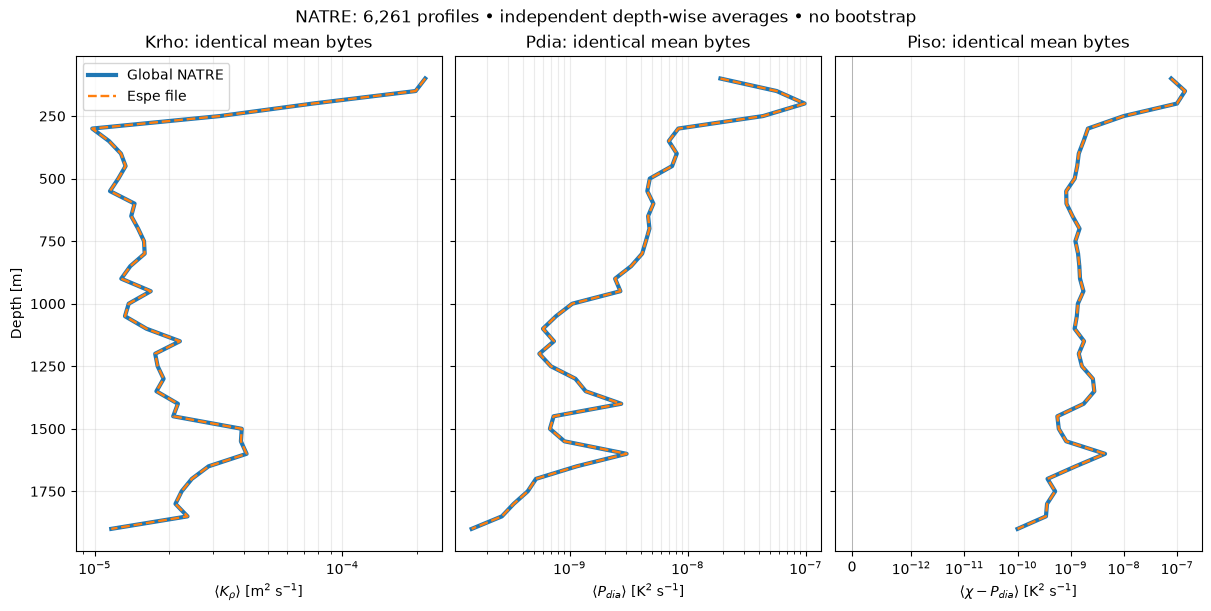

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True, constrained_layout=True)
for ax, name, label in zip(
    axes, ["Krho", "Pdia", "Piso"],
    [r"$\langle K_\rho\rangle$ [m$^2$ s$^{-1}$]",
     r"$\langle P_{dia}\rangle$ [K$^2$ s$^{-1}$]",
     r"$\langle \chi-P_{dia}\rangle$ [K$^2$ s$^{-1}$]"],
):
    ax.plot(global_means[name], global_means.Zfs, color="tab:blue", lw=3,
            label="Global NATRE")
    ax.plot(espe_means[name], espe_means.Zfs, color="tab:orange", ls="--", lw=1.7,
            label="Espe file")
    if name == "Piso":
        ax.set_xscale("symlog", linthresh=1e-12)
        ax.axvline(0, color="0.7", lw=0.7)
    else:
        ax.set_xscale("log")
    ax.set_xlabel(label)
    ax.grid(alpha=0.25, which="both")
    ax.set_title(name + ": identical mean bytes")
axes[0].set_ylabel("Depth [m]")
axes[0].invert_yaxis()
axes[0].legend()
fig.suptitle("NATRE: 6,261 profiles • independent depth-wise averages • no bootstrap")
plt.show()


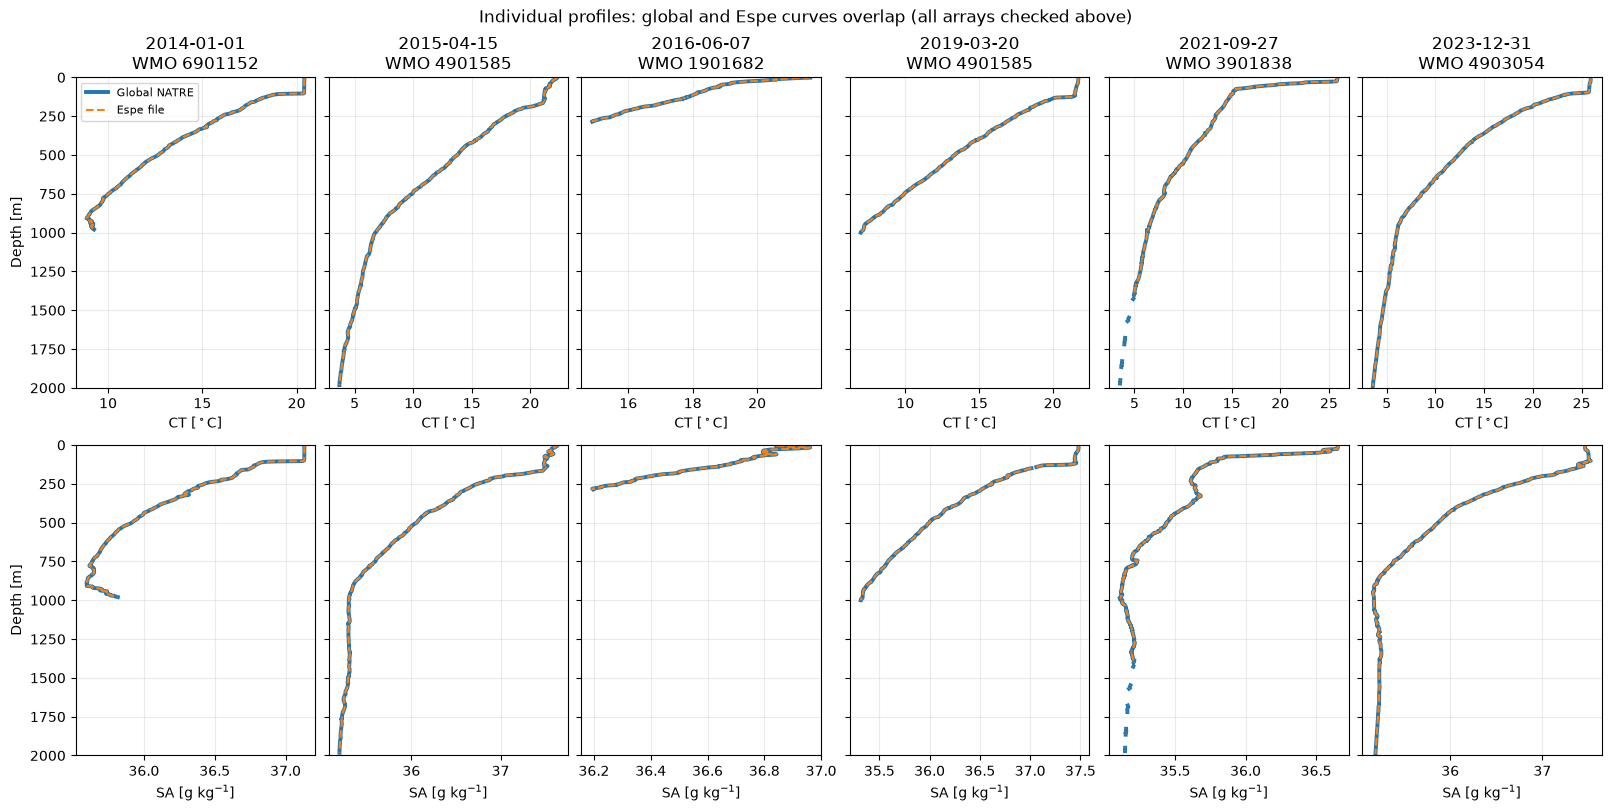

In [2]:
# Additional visual check: six profiles spanning the reference period.
# Indices depend only on the candidate length, not on an agreement search.
example_indices = np.linspace(0, natre_global.sizes["time"] - 1, 6, dtype=int)
fig, axes = plt.subplots(2, 6, figsize=(16, 8), sharey=True, constrained_layout=True)
for col, index in enumerate(example_indices):
    a, b = natre_global.isel(time=index), natre_espe.isel(time=index)
    for row, name, label in [(0, "CT", r"CT [$^\circ$C]"), (1, "SA", r"SA [g kg$^{-1}$]")]:
        ax = axes[row, col]
        ax.plot(a[name], a.Z, color="tab:blue", lw=2.8, label="Global NATRE")
        ax.plot(b[name], b.Z, color="tab:orange", ls="--", lw=1.5, label="Espe file")
        ax.set_xlabel(label)
        ax.grid(alpha=0.25)
    axes[0, col].set_title(str(a.time.values)[:10] + chr(10) + "WMO " + str(int(a.platform_number.values)))
axes[0, 0].set_ylim(2000, 0)
axes[0, 0].set_ylabel("Depth [m]")
axes[1, 0].set_ylabel("Depth [m]")
axes[0, 0].legend(fontsize=8)
fig.suptitle("Individual profiles: global and Espe curves overlap (all arrays checked above)")
plt.show()


In [8]:
assert coverage["same_population_with_multiplicity"] and coverage["same_order_after_independent_sort"]
assert array_checks.bitwise_equal.all() and mean_checks.bitwise_equal.all()
display(Markdown(
    "**PASS — 6,261/6,261 NATRE profiles; zero missing or extra profiles; "
    "34/34 reference data variables and 3/3 coordinates are bitwise identical.** "
    "The independently computed average Krho, Pdia and Piso profiles and counts "
    "also match bitwise. This verdict covers decoded reference arrays after "
    "independent profile ordering, not whole NetCDF files or the 14 extra global diagnostics."
))


**PASS — 6,261/6,261 NATRE profiles; zero missing or extra profiles; 34/34 reference data variables and 3/3 coordinates are bitwise identical.** The independently computed average Krho, Pdia and Piso profiles and counts also match bitwise. This verdict covers decoded reference arrays after independent profile ordering, not whole NetCDF files or the 14 extra global diagnostics.